<a href="https://colab.research.google.com/github/sredhagopan/AI-ML-Lab/blob/main/Decision_Tree_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Tree Classification
## Date: 16 Sept 2026

Accuracy: 0.8426966292134831


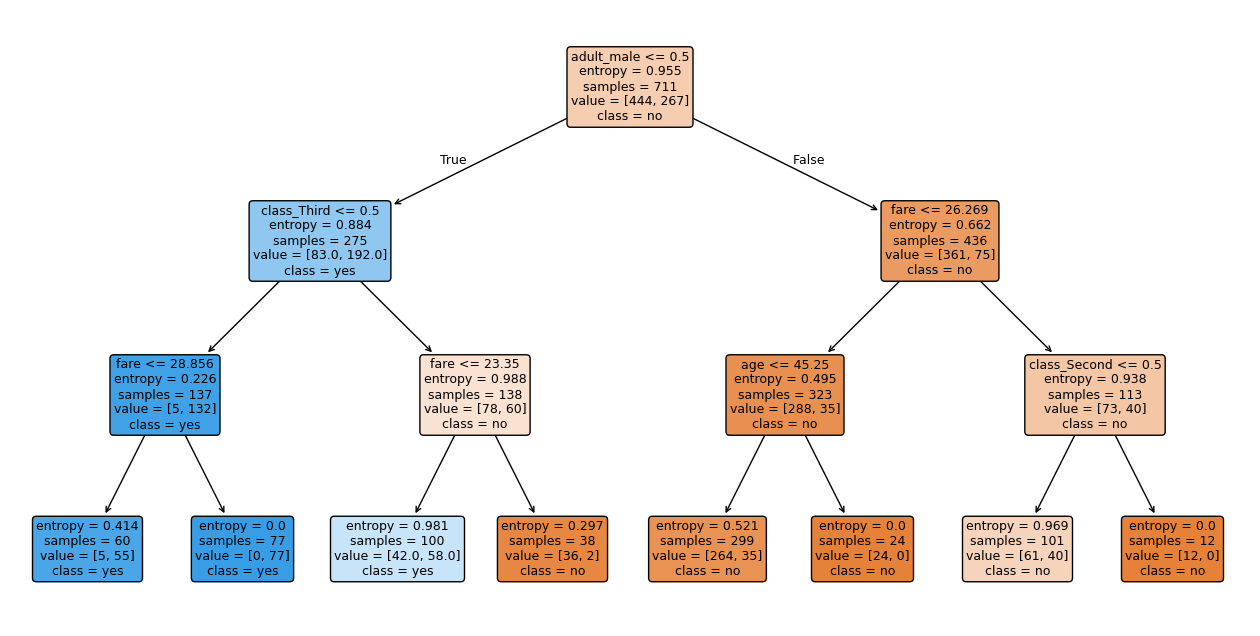

In [2]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
df = pd.read_csv('/content/titanic_data.csv')

# Remove survived column (duplicate of alive)
df = df.drop('survived', axis=1)

# Separate features and target
X = df.drop('alive', axis=1)
y = df['alive']

# Convert categorical columns into numerical values
X = pd.get_dummies(X, drop_first=True)

# Handle missing values
X = X.fillna(X.median())

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Decision Tree model
model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.show()